In [ ]:
"""
Esercizio 1
Confronto vendite mensili per prodotto: creare un dataset multi-store,
multi-prodotto e visualizzare le vendite mensili con subplot per store, 
aggiungendo legenda e annotazioni sui picchi.

"""

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 

np.random.seed(42)
stores = [
    "Store_Roma_01",
    "Store_Milano_02",
    "Store_Napoli_03",
    "Store_Torino_04",
]
products = [
    "Laptop Pro",
    "Smartphone X",
    "Auricolari Wireless",
    "Monitor 27\"",
    "Tastiera Meccanica",
]

date_rng = pd.date_range(start="2025-01-01", end="2025-12-31", freq="D")

data = []

base_prices = {
    "Laptop Pro": 1200.0,
    "Smartphone X": 800.0,
    "Auricolari Wireless": 150.0,
    "Monitor 27\"": 300.0,
    "Tastiera Meccanica": 90.0,
}


for date in date_rng:
    for product in products:

            store_price_factor = np.random.uniform(0.95, 1.05)
            unit_price = round(base_prices[product] * store_price_factor,2)

            is_weekend = 1 if date.dayofweek >= 5 else 0
            month_factor = 1.3 if date.month == 12 else 1.0

            base_demand = np.random.poisson(lam=5)
            units_sold = int (
                base_demand * (1.5 if is_weekend else 1.0) * month_factor
            )

            total_sales = round(units_sold * unit_price, 2)
            stock_left = np.random.randint(0,50)
            store = np.random.choice(stores)
            data.append({
                "Date": date,
                "Store_ID": store,
                "Product_Name": product,
                "Unit_Price": unit_price,
                "Units_Sold": units_sold,
                "Total_Sales": total_sales,
                "Stock_Left": stock_left,
            })

df = pd.DataFrame(data)

print(df.shape)
print(df.head(20))

df["Month"] = df["Date"].dt.to_period("M")
vendite_mensili_store = (
      df.groupby(["Month","Store_ID"])["Total_Sales"]
      .sum()
      .reset_index()
      .sort_values(by=["Month","Total_Sales"],ascending=[True, False])
)

print(vendite_mensili_store)
vendite_mensili_store["Month"] = vendite_mensili_store["Month"].astype(str)
stores = vendite_mensili_store["Store_ID"].unique()

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14,8), sharey=True)
axes = axes.flatten()

for i, store in enumerate(stores):
    store_data = vendite_mensili_store[vendite_mensili_store["Store_ID"] == store]
    ax = axes[i]

    ax.plot(
         store_data["Month"],
         store_data["Total_Sales"],
         marker="o",
         color="tab:blue",
         linewidth=2,
         label =f"Fatturato {store}"
    )

    ax.legend(loc="upper right")

    max_pos = np.argmax(store_data["Total_Sales"].values)
    max_row = store_data.iloc[max_pos]
    x_val = max_row["Month"] 
    y_val = max_row["Total_Sales"]

    ax.annotate(
         f"Picco: {y_val:,.0f}€",
         xy=(x_val, y_val),
         xytext=(0,20),
         textcoords="offset points",
         ha="center",
         fontsize=9,
         fontweight="bold",
         color="darkred",
         arrowprops=dict(
              arrowstyle="->", lw=1.5, color="darkred"
         ),
    )

    ax.set_title(f"Negozio: {store}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Mese", fontsize=10)
    ax.set_ylabel("Fatturato (€)", fontsize=10)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
""" 
Esercizio 2
Distribuzione utenti per categoria: simulare utenti e transazioni, 
usare scatter plot con color map per categorie, 
dimensioni dei marker proporzionali al numero di transazioni.

"""

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

np.random.seed(11)
n_users = 1000

user_ids = [f"USR_{i:04d}" for i in range(1, n_users + 1)]
user_categories = ['Base', 'Standard', 'Premium', 'VIP']
category_weights = [0.50, 0.30, 0.15, 0.05]

categories = np.random.choice(
    user_categories, size=n_users, p=category_weights
)

profili = {
    'Base': {'n_tx': (1, 3), 'spesa': (10, 40)},
    'Standard': {'n_tx': (3, 7), 'spesa': (40, 100)},
    'Premium': {'n_tx': (7, 15), 'spesa': (100, 250)},
    'VIP': {'n_tx': (15, 30), 'spesa': (250, 600)},
}


transactions = []
tx_counter = 1

for uid, cat in zip(user_ids, categories):
    p = profili[cat]
    n_tx = np.random.randint(p['n_tx'][0], p['n_tx'][len(p['n_tx'])-1]+1)

    for _ in range(n_tx):
        amount = round(np.random.uniform(p['spesa'][0], p['spesa'][len(p['spesa'])-1]),2)

        transactions.append(
            {
                'transaction_id':f'TX_{tx_counter:06d}',
                'user_id': uid,
                'category': cat,
                'amount': amount,
            }
        )
        tx_counter+=1

# DATAFRAME FINALE
df = pd.DataFrame(transactions)

print('--- Prime 5 righe del DataFrame ---')
print(df.head())
print('\n')


trans_categoria = df.groupby("category").size().reset_index(name='numero_transazioni')
print(trans_categoria)

# SCATTERPLOT DEL DATAFRAME AGGREGATO
colori = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

marker_sizes = trans_categoria['numero_transazioni'] * 0.5

# Creiamo lo scatter plot usando direttamente le colonne del dataframe
plt.scatter(
    trans_categoria['category'],
    trans_categoria['numero_transazioni'],
    color= colori,
    s=marker_sizes,
    alpha=0.6,
    zorder=3,
)

plt.title(
    'Numero Totale di Transazioni per Categoria (DataFrame Aggregato)',
    fontsize=14,
)

plt.xlabel('Categoria Utente', fontsize=12)
plt.ylabel('Numero Totale Transazioni', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5, zorder=0)



In [ ]:
""" 
Esercizio 3
Serie temporali con media mobile e soglie: creare serie giornaliere di traffico web, 
aggiungere media mobile, soglia criticità, e annotare i giorni con picchi.
"""

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

# ==========================================
# 1. GENERAZIONE DEL DATASET DI TRAFFICO WEB
# ==========================================
# Genera un intervallo di date giornaliere per tutto il 2025
dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")

# Imposta un seed casuale per garantire la riproducibilità dei dati generati
np.random.seed(123)

# Simula valori casuali di accessi web giornalieri compresi tra 100 e 1000
accessi = np.random.randint(100, 1000, len(dates))

# Crea il DataFrame Pandas che unisce le date ai rispettivi valori di traffico
df_web = pd.DataFrame({"data": dates, "accessi_web": accessi})

# Stampa le prime 10 righe per verificare la struttura del DataFrame
print(df_web.head(10))

# ==========================================
# 2. CALCOLO DELLE METRICHE MOBILI E SOGLIA
# ==========================================
# Calcola la media mobile a 7 giorni (smussa il trend escludendo le fluttuazioni giornaliere casuali)
df_web["MA7"] = df_web["accessi_web"].rolling(7).mean()

# Calcola la deviazione standard mobile a 7 giorni (misura la variabilità locale del traffico)
df_web["STD7"] = df_web["accessi_web"].rolling(7).std()

# Definisce una soglia critica dinamica: Media mobile + 2 volte la deviazione standard
# Tutto ciò che supera questa linea rappresenta un'anomalia statistica (picco insolito)
df_web["soglia_critica"] = df_web["MA7"] + (2 * df_web["STD7"])

# Filtra il DataFrame per individuare esattamente i giorni in cui gli accessi superano la soglia critica
picchi = df_web[df_web["accessi_web"] > df_web["soglia_critica"]]

# ==========================================
# 3. VISUALIZZAZIONE GRAFICA E ANNOTAZIONI
# ==========================================
plt.figure(figsize=(14, 6))

# Traccia i dati grezzi giornalieri con trasparenza per fare da sfondo
plt.plot(df_web["data"], df_web["accessi_web"], alpha=0.4, color="gray", label="Accessi web giornalieri")

# Traccia la linea della media mobile (il trend generale del traffico)
plt.plot(df_web["data"], df_web["MA7"], color="blue", linewidth=2, label="Media mobile 7 giorni")

# Traccia la soglia critica superiore (la linea di allerta statistica)
plt.plot(df_web["data"], df_web["soglia_critica"], color="crimson", linestyle="--", linewidth=1.5, label="Soglia Critica (MA7 + 2*STD)")

# Evidenzia visivamente i giorni di picco anomalo con punti rossi in primo piano
plt.scatter(picchi["data"], picchi["accessi_web"], color="red", zorder=5, label="Picchi Anomali")

# Cicla sui giorni critici trovati per aggiungere un'annotazione testuale sul grafico
for _, row in picchi.iterrows():
    plt.annotate(
        f"{int(row['accessi_web'])}", 
        (row["data"], row["accessi_web"]),
        textcoords="offset points", 
        xytext=(0, 10), 
        ha='center', 
        fontsize=8, 
        color="darkred",
        weight="bold"
    )

# Configurazione finale degli elementi estetici del grafico
plt.title("Traffico web: Monitoraggio con media mobile, soglia critica dinamica e picchi", fontsize=13, weight="bold")
plt.xlabel("Data")
plt.ylabel("Numero Accessi")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [ ]:
""" 
Esercizio 4
Heatmap di correlazioni: 
calcolare correlazioni tra più metriche di vendita, 
visualizzarle con colormap, 
aggiungere annotazioni numeriche.

"""
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

np.random.seed(42)
n_rows = 1000

# generazione di dati realistici per le vendite
dates = pd.date_range(pd.to_datetime("2026-01-01"), periods=n_rows, freq='D')
categorie = ["Elettronica", "Abbigliamento", "Casa", "Sport"]
canali = ["Online", "Negozio Fisico", "App Mobile"]

data = {
    "data": np.random.choice(dates, n_rows),
    "id_transazione":[f"TRX_{i:04d}" for i in range(n_rows)],
    "categoria": np.random.choice(categorie, n_rows, p=[0.3,0.4,0.2,0.1]),
    "canale_vendita": np.random.choice(canali, n_rows, p=[0.5,0.3,0.2]),
    "quantita": np.random.poisson(lam=2, size=n_rows)+1,
    "prezzo_unitario": np.random.uniform(10.0, 300.0, n_rows).round(2),
    "sconto_percentuale": np.random.choice([0.0,0.5,0.1,0.2,0.3], n_rows, p=[0.5, 0.2, 0.15, 0.1, 0.05]),
    "costi_spedizione": np.random.uniform(0.0,15.0,n_rows).round(2)
}

df_trans = pd.DataFrame(data)

df_trans["fatturato_totale"] = df_trans["prezzo_unitario"] * df_trans["quantita"] * (1 - df_trans["sconto_percentuale"]) + df_trans["costi_spedizione"]

# estrae le colonne numeriche e calcola la correlazione
matrice_corr = df_trans.select_dtypes(include=[np.number]).corr()

# creazione heatmap con matplotlib
fig, ax = plt.subplots(figsize=(8,6))
cax = ax.imshow(matrice_corr, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(cax)

colonne = matrice_corr.columns
ax.set_xticks(np.arange(len(colonne)))
ax.set_yticks(np.arange(len(colonne)))
ax.set_xticklabels(colonne, rotation=45, ha="right")
ax.set_yticklabels(colonne)

# scrive i valori numerici all'interno di ogni cella (come fa annot=True in Seaborn)
for i in range(len(colonne)):
    for j in range(len(colonne)):
        valore = matrice_corr.iloc[i,j]
        # sceglie il colore del testo (bianco o nero) in base alla scuro/chiaro della cella
        colore_testo = "white" if abs(valore) > 0.5 else "black"
        ax.text(j, i, f"{valore:.2f}", ha="center", va="center", color=colore_testo, weight="bold")

plt.title("Matrice di Correlazione (solo Matplotlib)", fontsize=12, weight="bold")
plt.tight_layout()
plt.show()

        data id_transazione      categoria  canale_vendita  quantita  \
0 2023-04-13       TRX_0000    Elettronica          Online         3   
1 2024-03-11       TRX_0001    Elettronica          Online         5   
2 2025-05-10       TRX_0002  Abbigliamento  Negozio Fisico         2   
3 2023-09-28       TRX_0003           Casa      App Mobile         3   
4 2023-04-17       TRX_0004          Sport          Online         2   
5 2023-03-13       TRX_0005    Elettronica      App Mobile         5   
6 2024-12-01       TRX_0006  Abbigliamento          Online         4   
7 2023-01-21       TRX_0007  Abbigliamento      App Mobile         7   
8 2024-09-06       TRX_0008          Sport          Online         2   
9 2023-05-02       TRX_0009           Casa          Online         3   

   prezzo_unitario  sconto_percentuale  costi_spedizione   store  \
0           235.00                 0.0             12.31  storeE   
1           244.31                 0.1              4.28  storeA   
2  

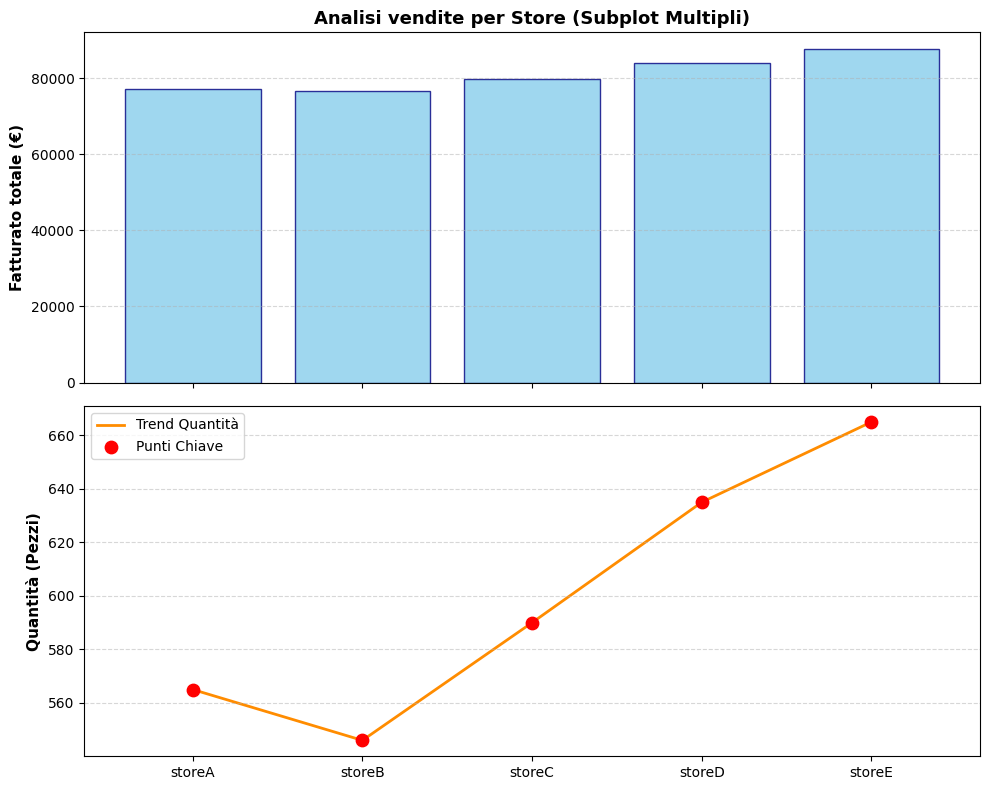

In [23]:
""" 
Esercizio 5
Dashboard multi-subplot: combinare line plot, 
bar plot e scatter plot per visualizzare vendite, 
unità e fatturato per più store, con layout leggibile e legenda comune.

"""

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

np.random.seed(42)
n_rows = 1000

# generazione di dati realistici per le vendite
dates = pd.date_range(pd.to_datetime("2023-01-01"), periods=n_rows, freq='D')
categorie = ["Elettronica", "Abbigliamento", "Casa", "Sport"]
canali = ["Online", "Negozio Fisico", "App Mobile"]

data = {
    "data": np.random.choice(dates, n_rows),
    "id_transazione":[f"TRX_{i:04d}" for i in range(n_rows)],
    "categoria": np.random.choice(categorie, n_rows, p=[0.3,0.4,0.2,0.1]),
    "canale_vendita": np.random.choice(canali, n_rows, p=[0.5,0.3,0.2]),
    "quantita": np.random.poisson(lam=2, size=n_rows)+1,
    "prezzo_unitario": np.random.uniform(10.0, 300.0, n_rows).round(2),
    "sconto_percentuale": np.random.choice([0.0,0.5,0.1,0.2,0.3], n_rows, p=[0.5, 0.2, 0.15, 0.1, 0.05]),
    "costi_spedizione": np.random.uniform(0.0,15.0,n_rows).round(2),
    "store": np.random.choice(["storeA", "storeB", "storeC", "storeD", "storeE"], size=n_rows)
}

df_trans2 = pd.DataFrame(data)
df_trans2["fatturato_totale"] = df_trans2["quantita"] * df_trans2["prezzo_unitario"] * (1 - df_trans2["sconto_percentuale"]) + df_trans2["costi_spedizione"]
print(df_trans2.head(10))

df_vendite = df_trans2.groupby("store")[["fatturato_totale","quantita"]].sum()

# creazione di una figura con 2 subplot verticali che condividono lo stesso asse X
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(10,8), sharex=True)

# subplot superiore: barplot per il fatturato
ax1.bar(df_vendite.index, df_vendite["fatturato_totale"], color="skyblue", edgecolor="navy", alpha=0.8)
ax1.set_ylabel("Fatturato totale (€)", fontsize=11, fontweight="bold")
ax1.set_title("Analisi vendite per Store (Subplot Multipli)", fontsize=13, fontweight="bold")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# subplot inferiore: lineplot + scatterplot per la quantità
ax2.plot(df_vendite.index, df_vendite["quantita"], color="darkorange",linewidth=2, label="Trend Quantità", zorder=1)
ax2.scatter(df_vendite.index, df_vendite["quantita"], color="red", s=80, label="Punti Chiave", zorder=2)
ax2.set_ylabel("Quantità (Pezzi)", fontsize=11, fontweight="bold")
ax2.legend(loc="upper left")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()